# 01 · Baseline phishing URL classifier

Goal for today: load a real labeled dataset, look at it, and train two classic models on **lexical URL features only** (nothing that requires visiting the page). We report **precision and recall on the phishing class**, because accuracy hides the errors that matter.

- **Recall** = of the actual phishing URLs, how many did we catch? A miss means someone clicks.
- **Precision** = of the URLs we flagged, how many were really phishing? Low precision means users learn to ignore warnings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from urllib.parse import urlsplit

from phishdetect.data import load_phiusiil
from phishdetect.features import featurize, FEATURE_NAMES

pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


## 1. Load the data
First run downloads ~235k URLs from UCI and caches them to `data/raw/phiusiil.csv` (git-ignored).

In [2]:
df = load_phiusiil()
df = df.drop_duplicates("url").reset_index(drop=True)
print(df.shape)
df.sample(8, random_state=RANDOM_STATE)

(235370, 2)


,url,is_phishing
142503,http://www.s107008.hostde20.fornex.host,1
175071,https://www.espresso4you.nl,0
33614,https://www.mazzios.com,0
68528,http://www.digitalkhulna.com,1
121610,http://www.pathregretforce.com,1
208897,https://www.jmrlsi.co.jp,0
59581,https://www.harborcountry-news.com,0
217393,http://www.baajaa.com,1


## 2. Explore

In [3]:
balance = df["is_phishing"].value_counts().rename({0: "legit", 1: "phishing"})
print(balance, "\n")
print((balance / len(df)).round(3))

is_phishing
legit       134850
phishing    100520
Name: count, dtype: int64 

is_phishing
legit       0.573
phishing    0.427
Name: count, dtype: float64


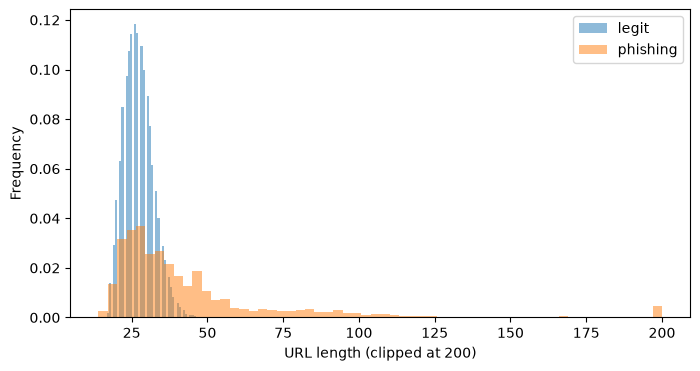

,count,mean,std,min,25%,50%,75%,max
is_phishing,,,,,,,,
0,134850.0,27.228610,4.815612,16.0,24.0,27.0,30.0,58.0
1,100520.0,46.221439,61.181745,14.0,26.0,34.0,48.0,6097.0


In [4]:
df["url_len"] = df["url"].str.len()
fig, ax = plt.subplots(figsize=(8, 4))
for label, name in [(0, "legit"), (1, "phishing")]:
    df.loc[df.is_phishing == label, "url_len"].clip(upper=200).plot.hist(
        bins=60, alpha=0.5, ax=ax, label=name, density=True)
ax.set_xlabel("URL length (clipped at 200)")
ax.legend(); plt.show()
df.groupby("is_phishing")["url_len"].describe()

In [5]:
def host_of(u):
    u = u if "://" in u else "http://" + u
    return (urlsplit(u).hostname or "").lower()

df["host"] = df["url"].map(host_of)
df["tld"] = df["host"].str.rsplit(".", n=1).str[-1]
for label, name in [(0, "legit"), (1, "phishing")]:
    print(f"--- top TLDs: {name}")
    print(df.loc[df.is_phishing == label, "tld"].value_counts().head(8), "\n")

--- top TLDs: legit
tld
com    68785
org    16524
uk      6073
net     3998
de      3310
au      2606
jp      2082
edu     1856
Name: count, dtype: int64 

--- top TLDs: phishing
tld
com    43608
app     6327
co      4950
io      3742
net     3078
ru      2978
top     2325
dev     2289
Name: count, dtype: int64 



### Sanity check: is the dataset leaking the answer?
Public phishing datasets often have collection artifacts, e.g. every legitimate URL was scraped from a top-sites list with the same prefix. A model can then score ~99% by learning the artifact instead of anything about phishing. Check how the URLs *start* in each class before trusting any score.

In [6]:
prefix = df["url"].str.extract(r"^(https?://(?:www\.)?)", expand=False).fillna("<no scheme>")
pd.crosstab(prefix, df["is_phishing"].map({0: "legit", 1: "phishing"}), normalize="columns").round(3)

is_phishing,legit,phishing
url,,
http://,0.0,0.123
http://www.,0.0,0.391
https://,0.0,0.462
https://www.,1.0,0.024


If one prefix shows up almost only in one class, the model will lean on it. Note what you find here; in the next notebook we can strip the scheme and `www.` before featurizing and see how much the score drops. That comparison is a great thing to talk about in an interview.

## 3. Features and split

In [7]:
%%time
X = featurize(df["url"])
y = df["is_phishing"].values
X.describe().T[["mean", "std", "min", "max"]]

CPU times: user 2.65 s, sys: 67.6 ms, total: 2.71 s
Wall time: 2.75 s


,mean,std,min,max
url_len,35.339920,41.233000,14.000000,6097.000000
host_len,21.454523,9.126058,4.000000,110.000000
path_len,3.721184,23.508432,0.000000,4248.000000
query_len,2.216170,24.902600,0.000000,3391.000000
n_dots,2.256995,0.922701,1.000000,99.000000
n_hyphens,0.349046,1.521875,0.000000,286.000000
n_digits,1.880898,11.898945,0.000000,2011.000000
n_special,0.221719,2.638367,0.000000,390.000000
n_subdomains,1.164894,0.600646,0.000000,10.000000
digit_ratio,0.028286,0.070184,0.000000,0.684211


In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, url_train, url_test = train_test_split(
    X, y, df["url"], test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(188296, 19) (47074, 19)


## 4. Train two baselines

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print("trained", name)

trained logreg
trained random_forest


## 5. Evaluate (phishing = positive class)

In [10]:
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             average_precision_score, classification_report)

rows = []
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "model": name,
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "PR-AUC": average_precision_score(y_test, proba),
        "accuracy": accuracy_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index("model").round(4)
results

,precision,recall,f1,PR-AUC,accuracy
model,,,,,
logreg,0.9978,0.9812,0.9894,0.9973,0.9911
random_forest,0.9989,0.9915,0.9952,0.9982,0.9959


In [11]:
best_name = results["PR-AUC"].idxmax()
best = models[best_name]
print("best:", best_name)
print(classification_report(y_test, best.predict(X_test), target_names=["legit", "phishing"], digits=4))

best: random_forest
              precision    recall  f1-score   support

       legit     0.9937    0.9992    0.9964     26970
    phishing     0.9989    0.9915    0.9952     20104

    accuracy                         0.9959     47074
   macro avg     0.9963    0.9953    0.9958     47074
weighted avg     0.9959    0.9959    0.9959     47074



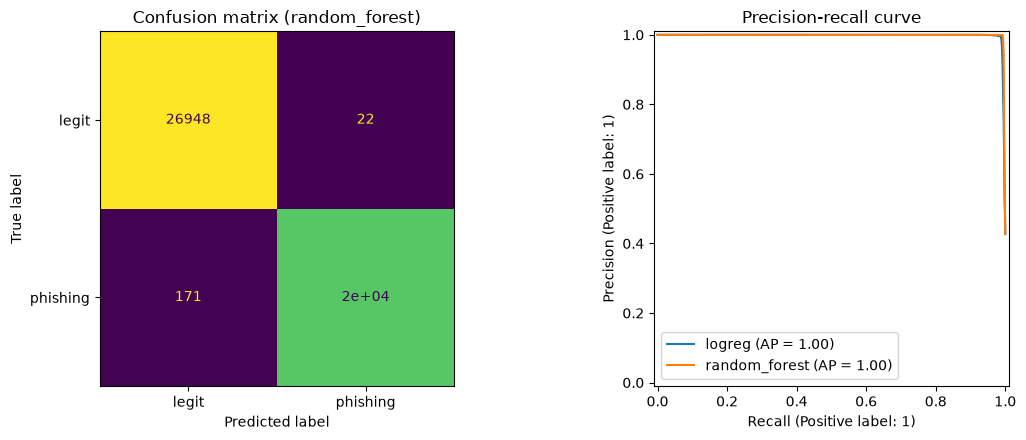

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["legit", "phishing"],
                                      ax=axes[0], colorbar=False)
for name, m in models.items():
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[0].set_title(f"Confusion matrix ({best_name})")
axes[1].set_title("Precision-recall curve")
plt.tight_layout(); plt.show()

### Picking a threshold
0.5 is arbitrary. A security tool usually wants high recall, so find the threshold that keeps recall at 95% or above and see what precision you pay for it.

In [13]:
from sklearn.metrics import precision_recall_curve
proba = best.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)
target_recall = 0.95
ok = np.where(rec[:-1] >= target_recall)[0]
i = ok[np.argmax(prec[ok])]
print(f"threshold={thr[i]:.3f}  precision={prec[i]:.4f}  recall={rec[i]:.4f}")

threshold=0.916  precision=1.0000  recall=0.9875


## 6. What did the model learn?

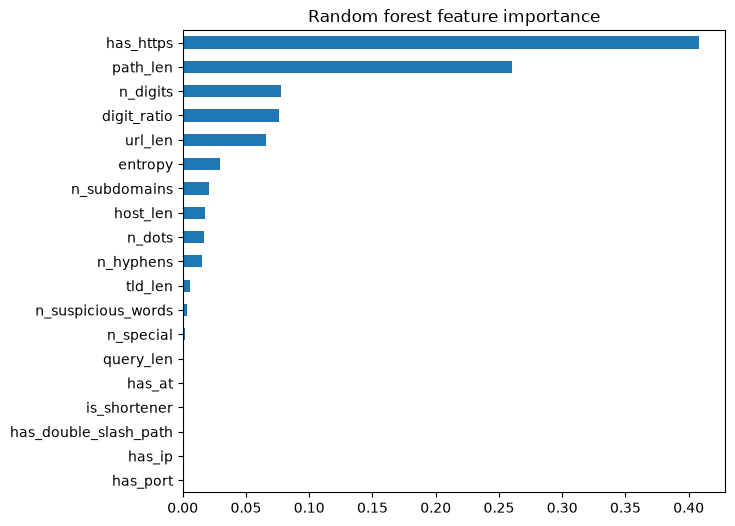

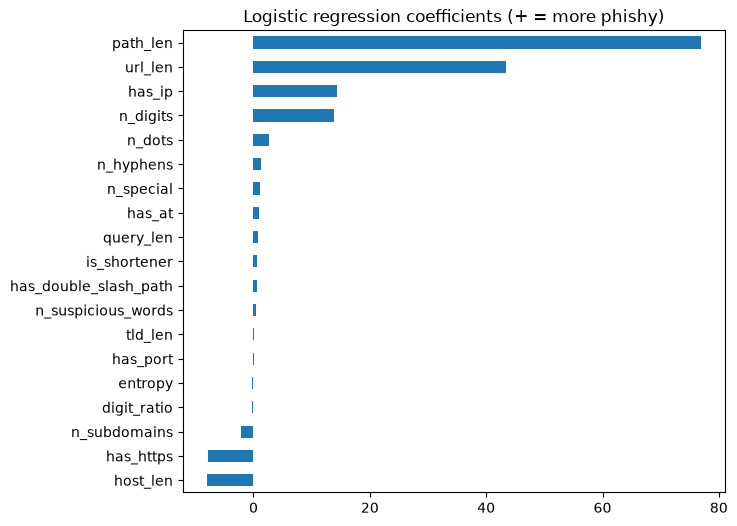

In [14]:
rf = models["random_forest"]
imp = pd.Series(rf.feature_importances_, index=FEATURE_NAMES).sort_values()
imp.plot.barh(figsize=(7, 6), title="Random forest feature importance"); plt.show()

coef = pd.Series(models["logreg"][-1].coef_[0], index=FEATURE_NAMES).sort_values()
coef.plot.barh(figsize=(7, 6), title="Logistic regression coefficients (+ = more phishy)"); plt.show()

## 7. Error analysis
Read the mistakes. This is where ideas for better features (and the deep learning stage) come from.

In [15]:
errs = pd.DataFrame({"url": url_test.values, "y": y_test, "p_phish": proba})
print("Missed phishing (false negatives), most confident first:")
display(errs[(errs.y == 1) & (errs.p_phish < 0.5)].sort_values("p_phish").head(15))
print("False alarms on legit URLs:")
display(errs[(errs.y == 0) & (errs.p_phish >= 0.5)].sort_values("p_phish", ascending=False).head(15))

Missed phishing (false negatives), most confident first:


,url,y,p_phish
23080,https://anpost.andahz.com,1,0.007514
10312,https://hatchpack.com.mx,1,0.007549
40696,https://www.rccgdrc.ca,1,0.007569
748,https://www.cfg.me,1,0.007573
4988,https://s.smcbazmzu.icu,1,0.007576
33594,https://www.faewood.com,1,0.007576
768,https://s.smcbacmzu.icu,1,0.007621
14710,https://ryyjv.mjcczp.cn,1,0.007630
11473,https://www.tkow.ink,1,0.007671
27156,https://www.metanfo.fr,1,0.007671


False alarms on legit URLs:


,url,y,p_phish
15379,https://www.180360.com,0,0.909435
43347,https://www.christoph-graupner-gesellschaft.de,0,0.770248
41038,https://www.standrewsgreekorthodoxcathedral.co.uk,0,0.719939
46681,https://www.commonfuture-paris2015.org,0,0.710769
25934,https://www.112112ww.com,0,0.707499
15750,https://www.check24-partnerprogramm.de,0,0.700549
46951,https://www.fussball-fanshop-24.de,0,0.696008
6033,https://www.wirtschaftsfoerderung-dortmund.de,0,0.690373
38631,https://www.formula1-dictionary.net,0,0.672539
21155,https://www.groupe-2v-services.com,0,0.621775


## 8. Save the model

In [16]:
import joblib, json
from phishdetect.data import PROJECT_ROOT
out = PROJECT_ROOT / "models"
joblib.dump(best, out / "baseline.joblib")
(out / "baseline_metrics.json").write_text(results.loc[best_name].to_json(indent=2))
print("saved to", out)

saved to /Users/simess/Desktop/Projects/phishing-detector/models


## Results log
Fill this in after running, and copy it into the README:

| model | precision | recall | PR-AUC | notes |
|---|---|---|---|---|
| logreg | | | | |
| random forest | | | | |

**Next notebook:** rerun with the scheme and `www.` stripped (leakage check), then try a char n-gram TF-IDF + logistic regression as a stronger baseline before moving to PyTorch.